# 01b · Noiseless ERN simulation (sanity check)

Same idea as `01_ern_simulation`, without noise or amplitude variability: 100 trials of ERN + Pe with Gaussian latency jitter (σ = 50 ms). With no noise, the induced power left after subtracting the evoked response comes from latency jitter alone, and Woody alignment should recover the true lags almost perfectly.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))  # make the repo's `ern_theta` package importable

import numpy as np
import matplotlib.pyplot as plt

from ern_theta import align_trials, compute_tfr, woody
from ern_theta.plotting import plot_lag_recovery, plot_tf_decomposition, plot_trials
from ern_theta.simulation import gaussian, simulate_trials

rng = np.random.default_rng(42)

sfreq = 500
tmin, tmax = -0.5, 1.0
times = np.linspace(tmin, tmax, int((tmax - tmin) * sfreq) + 1)
freqs = np.arange(1, 15, 1)

# Smaller components than in notebook 01
ERN = dict(peak_time=0.15, amplitude=-4.0, width=0.05)
PE = dict(peak_time=0.30, amplitude=7.0, width=0.07)

n_trials = 100
jitter_sd = 0.05  # s

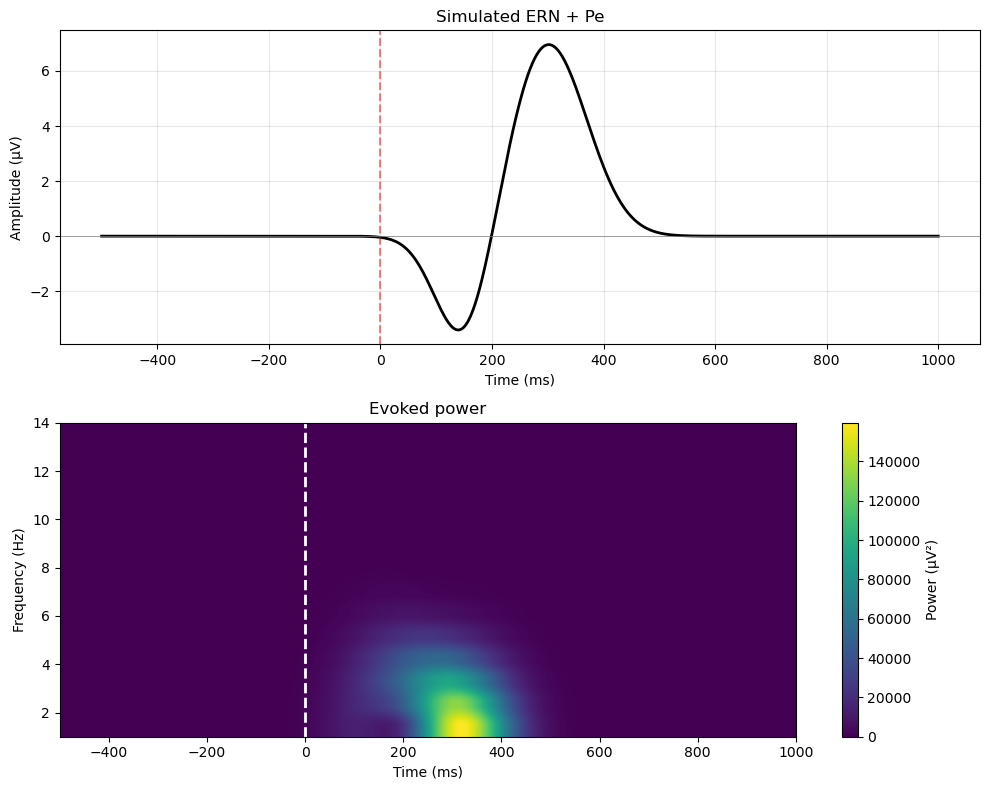

In [2]:
erp = gaussian(times, **ERN) + gaussian(times, **PE)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8))
ax1.plot(times * 1000, erp, 'k', linewidth=2)
ax1.axvline(0, color='r', linestyle='--', alpha=0.5)
ax1.axhline(0, color='gray', linewidth=0.5)
ax1.set_xlabel('Time (ms)')
ax1.set_ylabel('Amplitude (µV)')
ax1.set_title('Simulated ERN + Pe')
ax1.grid(alpha=0.3)

im = ax2.imshow(compute_tfr(erp, freqs, sfreq), aspect='auto', origin='lower',
                extent=[times[0] * 1000, times[-1] * 1000, freqs[0], freqs[-1]])
ax2.axvline(0, color='white', linestyle='--', linewidth=2)
ax2.set_xlabel('Time (ms)')
ax2.set_ylabel('Frequency (Hz)')
ax2.set_title('Evoked power')
plt.colorbar(im, ax=ax2, label='Power (µV²)')
plt.tight_layout()

## Jittered trials: total, evoked and induced power

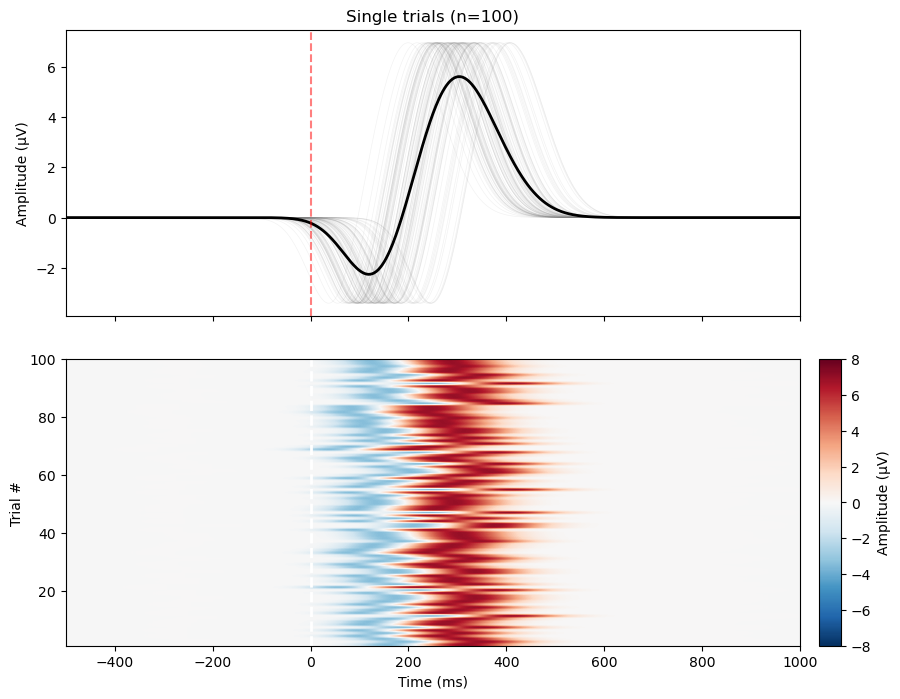

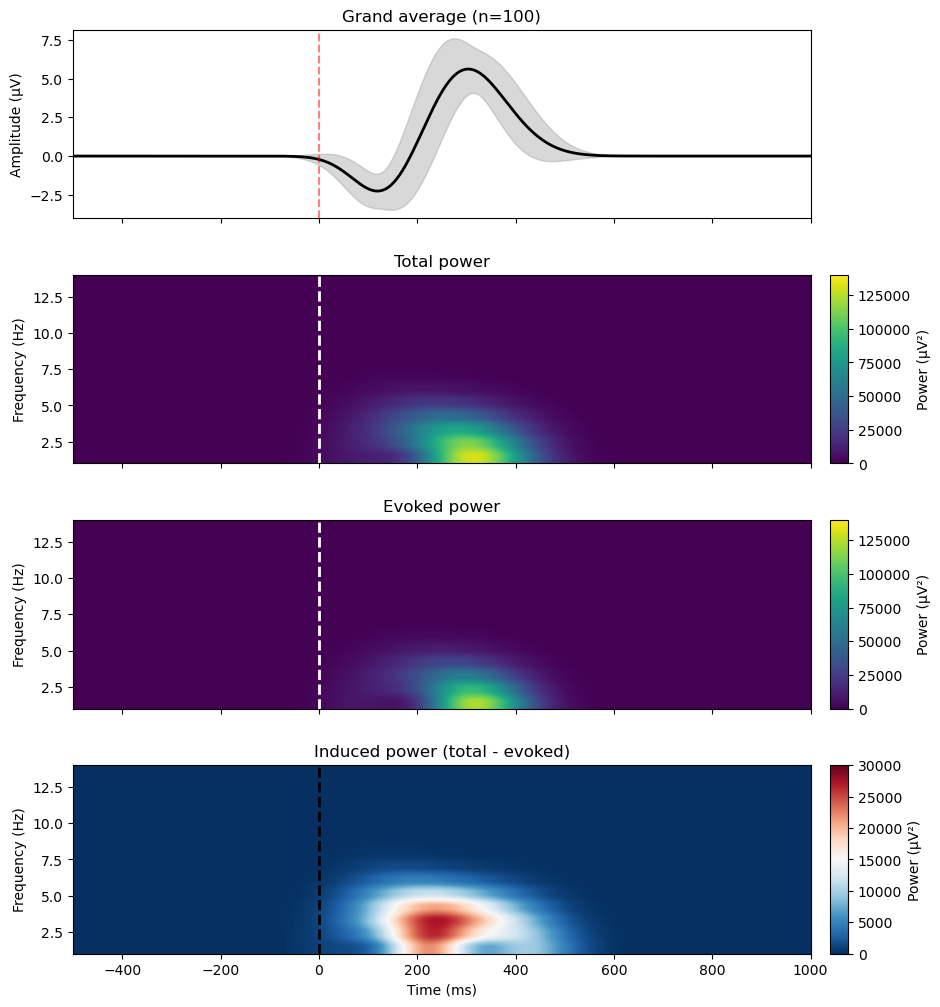

In [3]:
trials, true_jitters = simulate_trials(times, n_trials, rng, jitter_sd=jitter_sd,
                                      noise_amplitude=0, amplitude_jitter_sd=0,
                                      ern=ERN, pe=PE)

plot_trials(times, trials, f'Single trials (n={n_trials})', vlim=8, trace_alpha=0.1)
plot_tf_decomposition(times, freqs, trials,
                      compute_tfr(trials, freqs, sfreq),
                      compute_tfr(trials.mean(axis=0), freqs, sfreq));

## After Woody alignment

Correlation true vs detected lags: 0.999


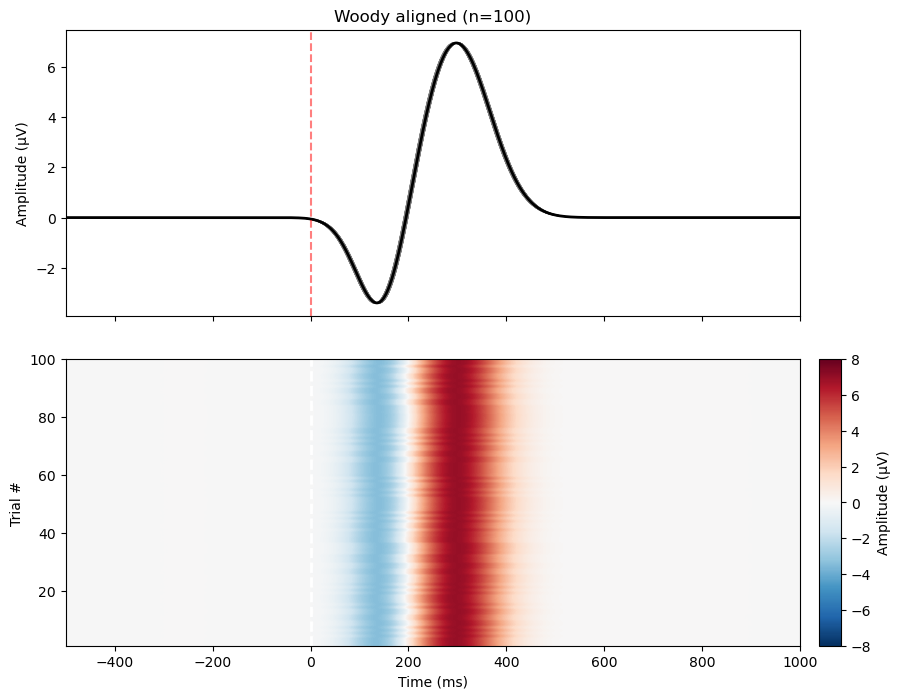

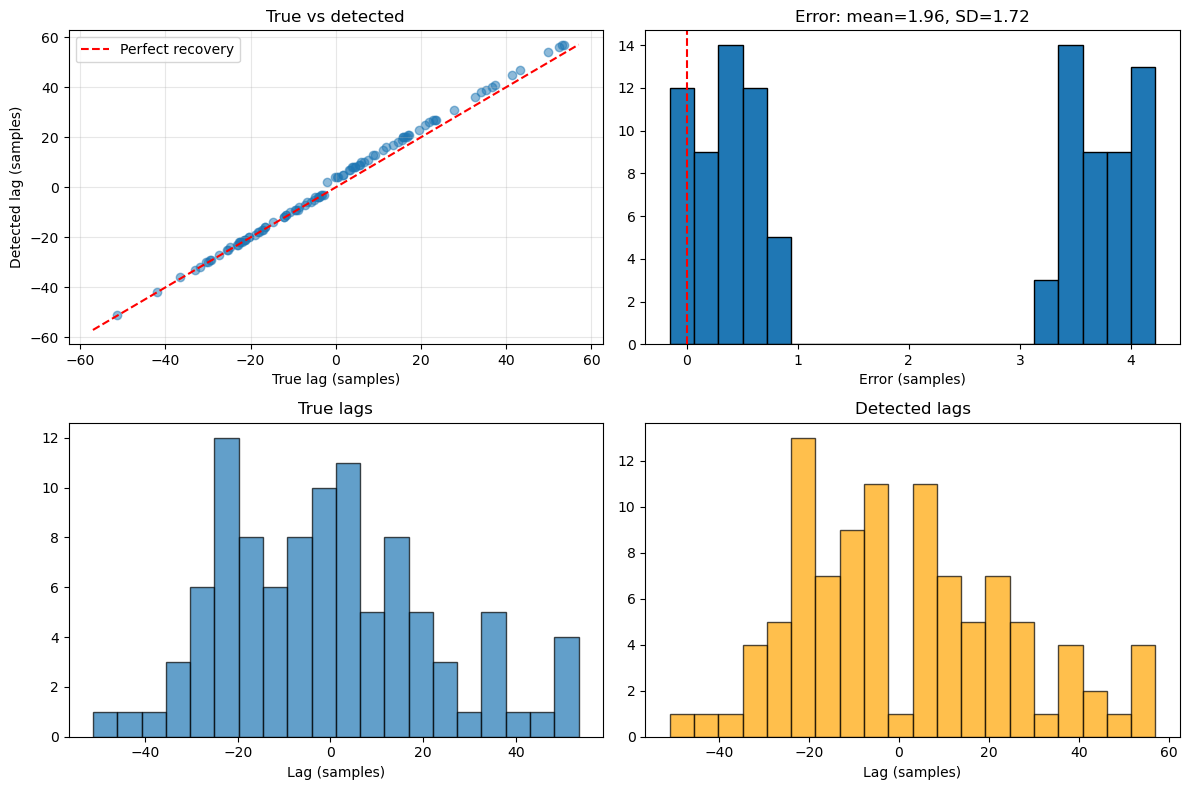

In [4]:
_, detected_lags = woody(trials.T, tol=0.1, max_it=100, est_mthd='woody', xcorr_mthd='unbiased')
aligned = align_trials(trials, detected_lags)

plot_trials(times, aligned, f'Woody aligned (n={n_trials})', vlim=8, trace_alpha=0.5)
plot_lag_recovery(true_jitters * sfreq, detected_lags);

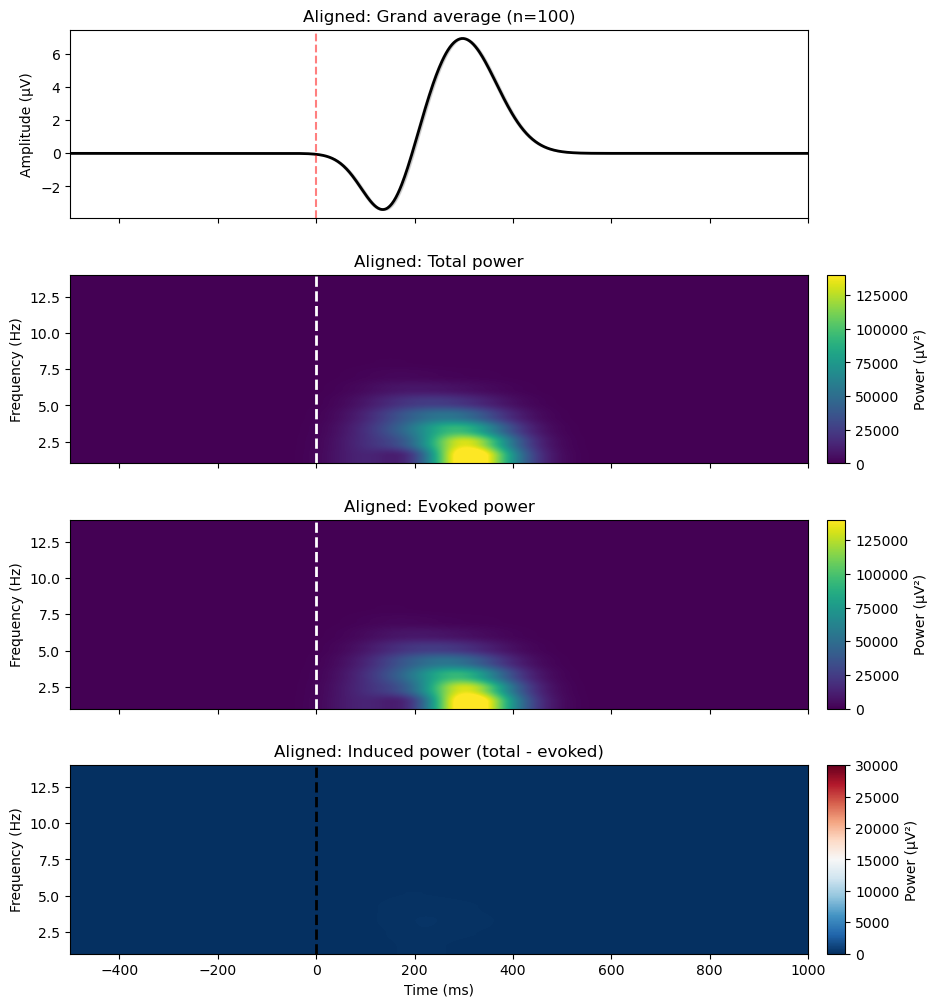

In [5]:
plot_tf_decomposition(times, freqs, aligned,
                      compute_tfr(aligned, freqs, sfreq),
                      compute_tfr(aligned.mean(axis=0), freqs, sfreq),
                      prefix='Aligned: ');